# Pre-Release Sales Prediction for Steam Games
## Notebook 3 of 3 — Modeling, Validation and Decision Making

This notebook trains and evaluates the three models on the table produced in Notebook 1:
**Linear Regression** and **Decision Tree** (the methods of the parent paper) and **Random Forest**.
All predictors are pre-release or release-day indicators (Notebook 1, Section 2.7). The target is
log10 owners relative to the release-year average (Notebook 1, Section 3.1).

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C"
MODEL_COLORS = {"Baseline (mean)": GREY, "Linear Regression": BLUE, "Decision Tree": ORANGE, "Random Forest": GREEN}

RANDOM_STATE = 42
DEV_END = pd.Timestamp("2021-12-31")
FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "feature_spec.json")) as f:
    spec = json.load(f)
GROUPS = spec["groups"]
FEATURES_PRE = [c for g in spec["pre_release_groups"] for c in GROUPS[g]]
FEATURES_ALL = FEATURES_PRE + [c for g in spec["release_day_groups"] for c in GROUPS[g]]
TARGET = "rel_log_owners"
print(f"{len(data):,} games | {len(FEATURES_PRE)} pre-release + {len(FEATURES_ALL) - len(FEATURES_PRE)} release-day indicators")

76,074 games | 57 pre-release + 5 release-day indicators


---
# 5. Data Split

## 5.1 Split design

The data are divided **chronologically** into two parts:

| Part | Release dates | Role |
|---|---|---|
| Development set | Jan 2010 – Dec 2021 | Model training, hyperparameter tuning and 5-fold cross-validation |
| Hold-out test set | Jan 2022 – Jun 2024 | Used once, after all modeling decisions are final (Section 7) |

**Why a chronological hold-out rather than a random one.** A pre-release forecast is always made
with a model trained on games that were released earlier. A random split would let the model learn
from games released after the ones it is tested on, which overstates the accuracy that could be
achieved in practice. Keeping the most recent releases aside reproduces the real forecasting
situation and tests whether relationships learned on 2010–2021 still hold for newer games.

**Why the hold-out is not used for tuning.** Any choice informed by the test set (for example, the
depth of the Decision Tree) would tailor the model to that set and bias its reported performance
upwards. All such choices are made with cross-validation inside the development set.

In [2]:
dev = data[data["release_dt"] <= DEV_END].reset_index(drop=True)
test = data[data["release_dt"] > DEV_END].reset_index(drop=True)

split_table = pd.DataFrame({
    "Release period": ["Jan 2010 – Dec 2021", "Jan 2022 – Jun 2024"],
    "Games": [len(dev), len(test)],
    "Share": [len(dev) / len(data), len(test) / len(data)],
    "Hit rate": [dev["is_hit"].mean(), test["is_hit"].mean()],
    "Target mean": [dev[TARGET].mean(), test[TARGET].mean()],
    "Target SD": [dev[TARGET].std(), test[TARGET].std()],
}, index=["Development", "Hold-out test"])
split_table.to_csv(os.path.join(TAB_DIR, "table2_data_split.csv"))
split_table.style.format({"Games": "{:,}", "Share": "{:.1%}", "Hit rate": "{:.1%}",
                          "Target mean": "{:.3f}", "Target SD": "{:.3f}"}) \
    .set_caption("Table 2. Development and hold-out sets")

,Release period,Games,Share,Hit rate,Target mean,Target SD
Development,Jan 2010 – Dec 2021,"47,476",62.4%,13.2%,0.000,0.537
Hold-out test,Jan 2022 – Jun 2024,"28,598",37.6%,5.4%,0.000,0.407


Because the target is defined relative to each release year, both sets have a target mean of zero
and a similar spread, even though raw hit rates differ between the periods (Notebook 2, Section 4.3).

## 5.2 Five-fold grouped cross-validation

Within the development set, models are compared and tuned with **5-fold cross-validation**: the
development set is divided into five folds; each model is trained on four folds and evaluated on the
fifth, and the process is repeated so that every game is used for evaluation exactly once. Reporting
the mean and standard deviation over five folds is more reliable than a single train/validation
split, whose result depends on which games happen to fall in the validation part.

**Grouping.** Folds are formed with `GroupKFold` on the normalised title key (Notebook 1, Section
2.6), so all AppIDs sharing a title are assigned to the same fold. Without grouping, a re-release
could appear in training while its original is being evaluated.

In [3]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
groups = dev["title_key"].values
folds = list(cv.split(dev, groups=groups))

fold_table = pd.DataFrame([
    {"Fold": k + 1, "Training games": len(tr), "Validation games": len(va),
     "Validation hit rate": dev.loc[va, "is_hit"].mean()}
    for k, (tr, va) in enumerate(folds)
]).set_index("Fold")
fold_table.style.format({"Training games": "{:,}", "Validation games": "{:,}", "Validation hit rate": "{:.1%}"})

,Training games,Validation games,Validation hit rate
Fold,,,
1,"37,976","9,500",13.0%
2,"37,965","9,511",12.8%
3,"37,993","9,483",13.3%
4,"37,998","9,478",13.7%
5,"37,972","9,504",13.4%


## 5.3 Evaluation metrics

The metrics of the parent paper are retained so that results can be compared directly, and one
classification metric is added:

| Metric | Scale | Interpretation |
|---|---|---|
| MSE, RMSE | Target (log10 relative owners) | Penalises large errors; RMSE of 0.30 ≈ predictions typically within a factor of 2 |
| MAE | Target | Average absolute error; less sensitive to extreme games |
| MAPE (%) | Owners | Average percentage error after converting predictions back to owner counts |
| R² | Target | Share of variance explained; 0 = no better than predicting the average |
| Hit ROC-AUC | Ranking | Probability that a randomly chosen hit (≥100k owners) is ranked above a randomly chosen non-hit; 0.5 = chance |

MAPE is computed on the owner scale because the relative target is centred on zero, where
percentage errors are undefined. Predictions are converted with
`owners = 10^(prediction + release-year average)`.

**Caveat on MAPE.** MAPE is reported for comparability with the parent paper but is not used to
select models. Percentage errors are asymmetric: over-predicting a game with 10,000 owners by a
factor of three counts as a 200% error, while under-predicting a game with 1,000,000 owners by the
same factor counts as 67%. Because about 70% of games sit in the lowest owner range, MAPE rewards
models that predict uniformly low values and penalises models that correctly identify the few
large successes. Model selection relies on R², MAE and hit ROC-AUC.

In [4]:
def compute_metrics(frame, pred):
    y = frame[TARGET].values
    owners_pred = 10 ** (pred + frame["cohort_mean_log_owners"].values)
    owners_true = frame["owners_mid"].values
    return {
        "MSE": mean_squared_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "MAE": mean_absolute_error(y, pred),
        "MAPE (%)": 100 * np.mean(np.abs(owners_pred - owners_true) / owners_true),
        "R2": r2_score(y, pred),
        "Hit ROC-AUC": roc_auc_score(frame["is_hit"], pred) if np.ptp(pred) > 0 else 0.5,
    }


def cross_validate_model(model, features, frame=dev, fold_list=folds):
    # Fit on four folds, evaluate on the fifth; return per-fold metrics and out-of-fold predictions.
    rows, oof = [], np.zeros(len(frame))
    for k, (tr, va) in enumerate(fold_list):
        m = clone(model).fit(frame.loc[tr, features], frame.loc[tr, TARGET])
        oof[va] = m.predict(frame.loc[va, features])
        rows.append({"fold": k + 1, **compute_metrics(frame.loc[va], oof[va])})
    return pd.DataFrame(rows).set_index("fold"), oof


def summarise(fold_metrics):
    return fold_metrics.agg(["mean", "std"]).T


def one_standard_error_choice(search, simplicity_order):
    # Simplest setting whose mean validation score is within one standard error of the best.
    # `simplicity_order` is a list of (column, ascending) pairs; the first row after sorting is the simplest.
    res = pd.DataFrame(search.cv_results_)
    best = res.loc[res["mean_test_score"].idxmax()]
    se = best["std_test_score"] / np.sqrt(len(folds))
    eligible = res[res["mean_test_score"] >= best["mean_test_score"] - se].copy()
    cols, asc = zip(*simplicity_order)
    chosen = eligible.sort_values(list(cols), ascending=list(asc)).iloc[0]
    return chosen["params"], chosen["mean_test_score"], best["mean_test_score"], se


cv_results = {}

---
# 6. Modeling

## 6.1 Feature set and preprocessing

The main feature set contains all 62 pre-release and release-day indicators. The contribution of
the release-day group is measured separately in Section 7.3.

Each model is wrapped in a scikit-learn `Pipeline` so that every preprocessing step is fitted only
on the training folds:
- **Imputation.** `log_lead_days` is missing for about 0.4% of games (Notebook 1, Section 3.2). It is
  filled with the training-fold median; the `lead_missing` flag preserves the information that the
  value was absent. Fitting the imputer on all data would pass information from the validation fold
  into training.
- **Standardisation (Linear Regression only).** Indicators are rescaled to mean 0 and standard
  deviation 1, so that coefficients are comparable across indicators measured in different units.
  Tree-based models split on thresholds and are unaffected by scaling.

## 6.2 Baseline

A model that always predicts the development-set mean. Any useful model must improve on it; by
construction its R² is approximately zero and its ROC-AUC is 0.5.

In [5]:
baseline = DummyRegressor(strategy="mean")
fm, _ = cross_validate_model(baseline, FEATURES_ALL)
cv_results["Baseline (mean)"] = fm
summarise(fm).round(4)

,mean,std
MSE,0.2884,0.0088
RMSE,0.5369,0.0082
MAE,0.4093,0.0045
MAPE (%),98.8813,1.5794
R2,-0.0003,0.0003
Hit ROC-AUC,0.5000,0.0000


## 6.3 Linear Regression

**Method.** Ordinary least squares estimates one coefficient per indicator so that the weighted sum
of indicators minimises the squared error against the target. It is the primary model of the parent
paper and the most interpretable of the three: each coefficient states how the prediction changes
when one indicator increases and all others are held constant.

**Limitations relevant to this data.** The model is additive and linear in each indicator. Notebook 2
showed non-monotone relationships (hit rate peaks at 9–15 languages and at 3–10 prior releases) and
likely interactions (for example, price matters differently for free and paid games). Linear
Regression can represent these only approximately. It has no hyperparameters to tune.

In [6]:
lin_reg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
fm, oof_lr = cross_validate_model(lin_reg, FEATURES_ALL)
cv_results["Linear Regression"] = fm
fm.round(4)

,MSE,RMSE,MAE,MAPE (%),R2,Hit ROC-AUC
fold,,,,,,
1,0.2189,0.4679,0.3413,103.7972,0.2271,0.7683
2,0.2089,0.4570,0.3347,94.8540,0.2425,0.7815
3,0.2132,0.4617,0.3385,92.9326,0.2797,0.7846
4,0.2183,0.4672,0.3418,95.7782,0.2632,0.7814
5,0.2194,0.4684,0.3411,102.2408,0.2437,0.7727


**Coefficients.** The model is refitted on the full development set. Coefficients are in target
units per one standard deviation of the indicator; `10^coefficient` converts them into a
multiplicative effect on owners (for example, 0.10 → ×1.26).

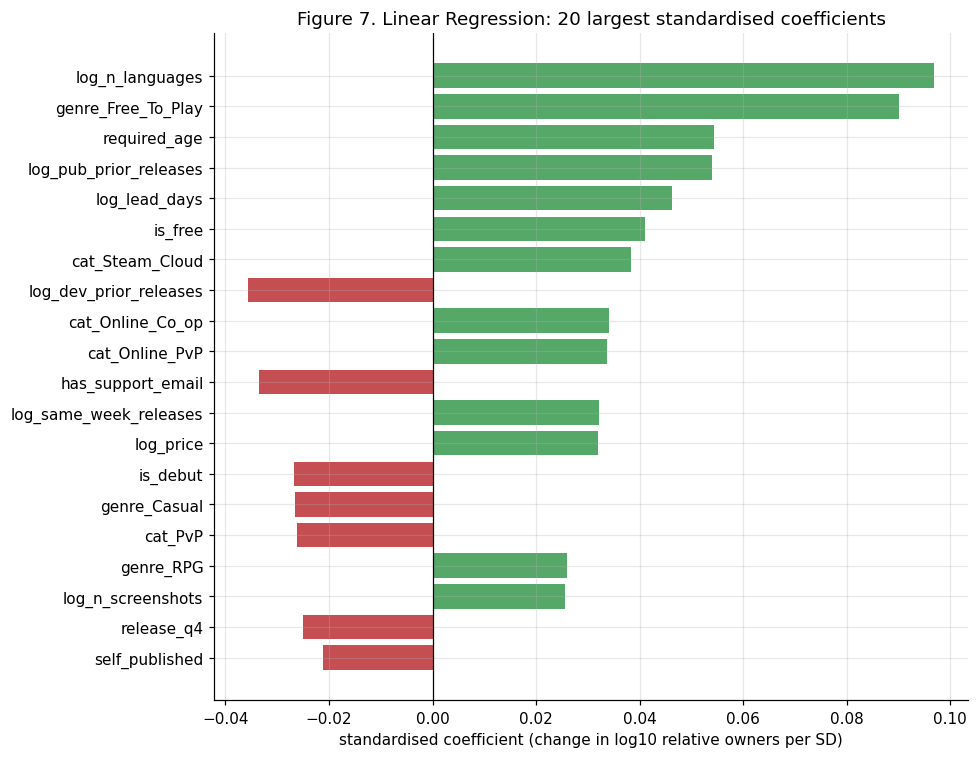

Intercept: 0.0000


,coefficient (per SD),owner multiplier
log_n_languages,0.097,1.250
genre_Free_To_Play,0.090,1.231
required_age,0.054,1.133
log_pub_prior_releases,0.054,1.132
log_lead_days,0.046,1.112
is_free,0.041,1.099
cat_Steam_Cloud,0.038,1.092
log_dev_prior_releases,-0.036,0.921
cat_Online_Co_op,0.034,1.082
cat_Online_PvP,0.034,1.081


In [7]:
lin_reg_dev = clone(lin_reg).fit(dev[FEATURES_ALL], dev[TARGET])
coef = pd.Series(lin_reg_dev.named_steps["linearregression"].coef_, index=FEATURES_ALL)
coef_table = pd.DataFrame({"coefficient (per SD)": coef, "owner multiplier": 10 ** coef})
coef_table = coef_table.reindex(coef.abs().sort_values(ascending=False).index)
coef_table.to_csv(os.path.join(TAB_DIR, "table3_linear_regression_coefficients.csv"))

top = coef_table.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top["coefficient (per SD)"], color=np.where(top["coefficient (per SD)"] > 0, GREEN, RED))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("standardised coefficient (change in log10 relative owners per SD)")
ax.set_title("Figure 7. Linear Regression: 20 largest standardised coefficients")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig07_linear_regression_coefficients.png"), dpi=150)
plt.show()
print(f"Intercept: {lin_reg_dev.named_steps['linearregression'].intercept_:.4f}")
coef_table.head(20).style.format("{:.3f}").set_caption("Table 3. Linear Regression: 20 largest standardised coefficients")

**Results.** Linear Regression explains about a quarter of the variance in the development set (5-fold R² = 0.251 ± 0.020) and ranks hits well above chance (hit ROC-AUC = 0.778). Performance is stable across folds.

**Interpretation of the coefficients (Table 3).**
- **Localisation** has the largest effect: one standard deviation more supported languages is associated with 1.25 times the owners of a typical game released in the same year.
- **Price.** Free-to-play and free games reach more owners, and among paid games a higher list price is also associated with more owners (log price +0.032). Price therefore acts as a signal of production scale rather than as a barrier to purchase.
- **Studio experience.** Publisher experience is positive (×1.13 per SD), while developer experience and the debut flag are negative once publisher experience is held constant. The three indicators are correlated (Notebook 2, Section 4.6) and should be read together: games released through experienced publishers do better, whereas developers with very large catalogues tend to release many small titles.
- **Store-page lead time** (×1.11 per SD) and **online multiplayer design** (online co-op and online PvP, each ×1.08) are positive.
- **Required age** is positive, likely because an age gate usually accompanies a formal content rating, which is more common for larger commercial releases.
- Two coefficients have no clear causal reading: providing a support e-mail address is negative, and the number of same-week releases is positive. Both are likely proxies for other characteristics (publisher type and seasonal release timing) and are not interpreted further.

The intercept is zero because the target is centred within each release year and all indicators are standardised.

## 6.4 Decision Tree

**Method.** A regression tree splits the data recursively on the indicator threshold that most
reduces squared error, and predicts the mean target of the games in each final leaf. It captures
non-linear effects and interactions without specifying them in advance and produces explicit
decision rules. It is the second model of the parent paper.

**Issue: overfitting.** An unconstrained tree keeps splitting until leaves contain very few games,
memorising noise in the training data. The parent paper used Orange's default settings (maximum
depth 100, two games per leaf), which allow this. **Solution:** the maximum depth and the minimum
number of games per leaf are tuned by 5-fold grouped cross-validation on the development set. The
comparison of training and validation R² in Figure 8 shows the point at which additional depth
stops generalising.

**Selection rule.** Several settings reach almost the same validation R², and the differences
between them are smaller than the variation from fold to fold. Choosing the single highest score
would partly select for noise. The **one-standard-error rule** (Hastie, Tibshirani and Friedman,
*The Elements of Statistical Learning*, 2009) is therefore applied: among all settings whose mean
validation R² lies within one standard error of the best, the simplest is chosen (smallest depth,
then largest leaf size).

Grid search: 40 settings x 5 folds in 28s


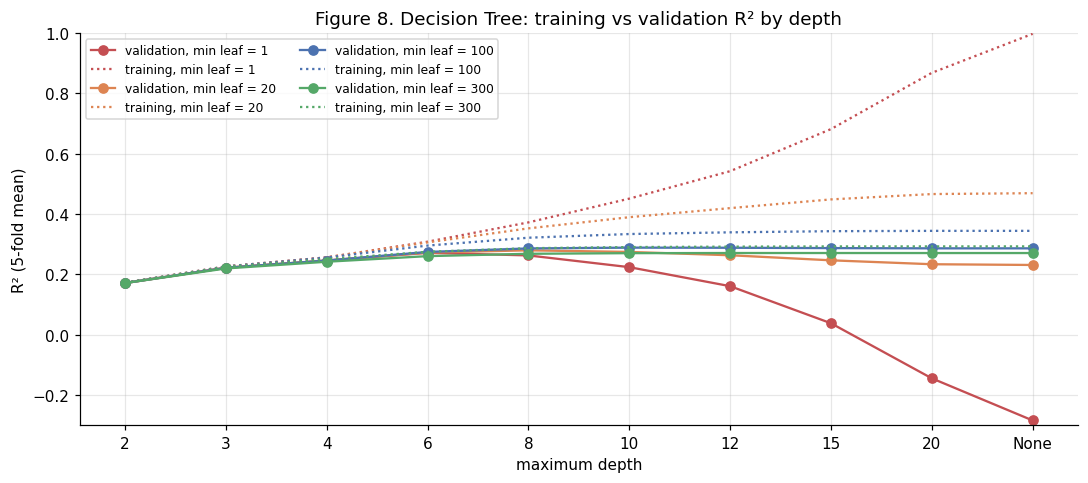

Highest validation R2: 0.2888 ({'max_depth': 10, 'min_samples_leaf': 100}), one standard error = 0.0075
Selected settings (one-standard-error rule): {'max_depth': 8, 'min_samples_leaf': 100} | validation R2 = 0.2862


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_13052\1236734641.py:31: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tr["depth_rank"] = tr["param_decisiontreeregressor__max_depth"].astype(object).fillna(10_000).astype(float)


In [8]:
tree_pipe = make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(random_state=RANDOM_STATE))
tree_grid = {
    "decisiontreeregressor__max_depth": [2, 3, 4, 6, 8, 10, 12, 15, 20, None],
    "decisiontreeregressor__min_samples_leaf": [1, 20, 100, 300],
}
t0 = time.time()
tree_search = GridSearchCV(tree_pipe, tree_grid, cv=folds, scoring="r2", return_train_score=True, n_jobs=-1)
tree_search.fit(dev[FEATURES_ALL], dev[TARGET])
print(f"Grid search: {len(tree_search.cv_results_['params'])} settings x 5 folds in {time.time() - t0:.0f}s")

tr = pd.DataFrame(tree_search.cv_results_)
tr["max_depth"] = tr["param_decisiontreeregressor__max_depth"].astype(object).fillna("None")
tr["min_samples_leaf"] = tr["param_decisiontreeregressor__min_samples_leaf"]
depth_labels = [str(d) for d in tree_grid["decisiontreeregressor__max_depth"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
for leaf, color in zip(tree_grid["decisiontreeregressor__min_samples_leaf"], [RED, ORANGE, BLUE, GREEN]):
    sub = tr[tr["min_samples_leaf"] == leaf]
    sub = sub.set_index(sub["max_depth"].astype(str)).reindex(depth_labels)
    ax.plot(depth_labels, sub["mean_test_score"], marker="o", color=color, label=f"validation, min leaf = {leaf}")
    ax.plot(depth_labels, sub["mean_train_score"], ls=":", color=color, label=f"training, min leaf = {leaf}")
ax.set_xlabel("maximum depth")
ax.set_ylabel("R² (5-fold mean)")
ax.set_ylim(-0.3, 1.0)
ax.set_title("Figure 8. Decision Tree: training vs validation R² by depth")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig08_decision_tree_validation_curve.png"), dpi=150)
plt.show()

tr["depth_rank"] = tr["param_decisiontreeregressor__max_depth"].astype(object).fillna(10_000).astype(float)
tree_search.cv_results_["depth_rank"] = tr["depth_rank"].values
best_tree_params, chosen_r2, top_r2, se = one_standard_error_choice(
    tree_search, [("depth_rank", True), ("param_decisiontreeregressor__min_samples_leaf", False)])
print(f"Highest validation R2: {top_r2:.4f} ({ {k.split('__')[1]: v for k, v in tree_search.best_params_.items()} }), "
      f"one standard error = {se:.4f}")
print("Selected settings (one-standard-error rule):", {k.split("__")[1]: v for k, v in best_tree_params.items()},
      f"| validation R2 = {chosen_r2:.4f}")

In [9]:
decision_tree = clone(tree_pipe).set_params(**best_tree_params)
fm, oof_dt = cross_validate_model(decision_tree, FEATURES_ALL)
cv_results["Decision Tree"] = fm
fm.round(4)

,MSE,RMSE,MAE,MAPE (%),R2,Hit ROC-AUC
fold,,,,,,
1,0.2092,0.4574,0.3268,109.2673,0.2613,0.7575
2,0.1987,0.4457,0.3213,93.0264,0.2795,0.7512
3,0.2061,0.4539,0.3300,96.9075,0.3037,0.7549
4,0.2100,0.4582,0.3302,108.0590,0.2913,0.7684
5,0.2046,0.4523,0.3255,94.3891,0.2949,0.7540


**Top of the fitted tree.** The first splits show which indicators the tree considers most
informative. Each node reports the split rule, the number of games, and the mean target value.

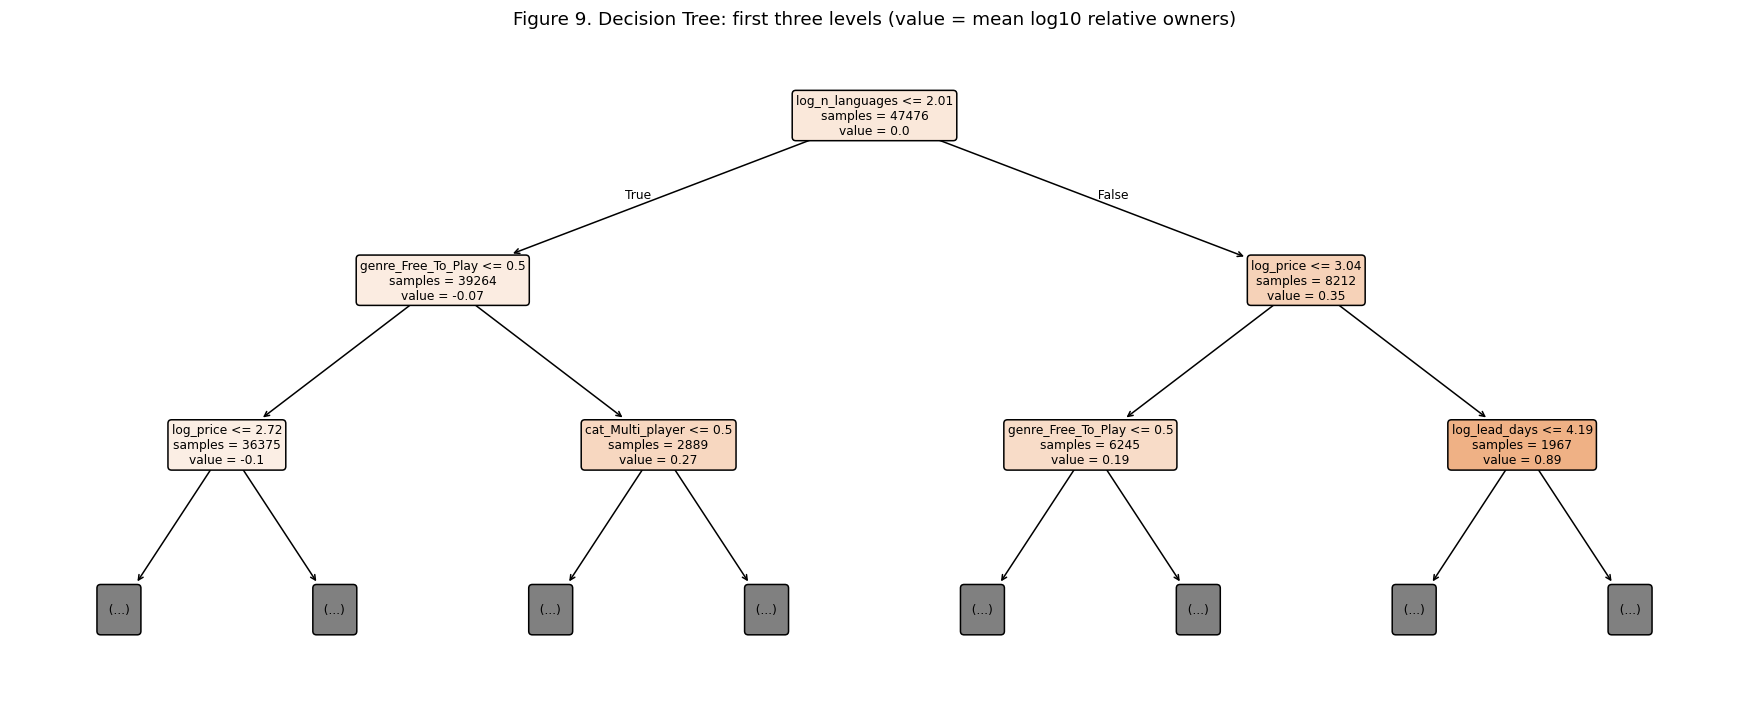

In [10]:
tree_dev = clone(decision_tree).fit(dev[FEATURES_ALL], dev[TARGET])
fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(tree_dev.named_steps["decisiontreeregressor"], max_depth=2, feature_names=FEATURES_ALL,
          filled=True, impurity=False, rounded=True, precision=2, fontsize=8, ax=ax)
ax.set_title("Figure 9. Decision Tree: first three levels (value = mean log10 relative owners)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig09_decision_tree_top_levels.png"), dpi=150)
plt.show()

**Results.** Figure 8 illustrates the overfitting problem directly. With no depth limit and one game per leaf, the tree fits the training folds almost perfectly (training R² ≈ 1.00) but scores R² = −0.28 on the validation folds, worse than predicting the average. This configuration is close to the Orange defaults used in the parent paper. Requiring at least 100 games per leaf keeps validation R² stable as depth increases.

The highest validation R² (0.289) was reached at depth 10 with 100 games per leaf; the one-standard-error rule selects **depth 8 with 100 games per leaf** (R² = 0.286, within one standard error of 0.0075). In cross-validation the tuned tree reaches R² = 0.286 ± 0.016, above Linear Regression, but a lower hit ROC-AUC (0.757 versus 0.778): a tree assigns the same prediction to every game in a leaf, so it ranks games less finely than a continuous model.

**Top of the tree (Figure 9).** The first split is on localisation (six or fewer supported languages versus seven or more). Among games with seven or more languages, price is the next split, and the 1,967 games priced above about $20 average +0.89 on the target, roughly 7.8 times the typical owner count of their release year. Among games with fewer languages, the free-to-play genre and price define the next splits. The tree therefore reproduces, as explicit rules, the main relationships found in Notebook 2.

## 6.5 Random Forest

**Method.** A Random Forest trains many decision trees, each on a bootstrap sample of the games and
considering only a random subset of indicators at every split, and averages their predictions.

**Why it is added.** A single tree is unstable: small changes in the training data can produce a
different tree and different predictions (high variance). Averaging many decorrelated trees keeps
the tree's ability to model non-linear effects and interactions while greatly reducing this
variance. It is therefore the natural extension of the parent paper's Decision Tree.

**Hyperparameters.** The number of trees is fixed at 200; adding trees does not cause overfitting,
it only increases computation. Two settings that control the bias–variance trade-off are tuned by
5-fold grouped cross-validation:
- `min_samples_leaf` — the minimum number of games in a leaf (larger values give smoother predictions);
- `max_features` — the share of indicators considered at each split (smaller values decorrelate the trees).

The one-standard-error rule from Section 6.4 is applied, with larger leaves and fewer candidate
indicators per split counted as simpler.

In [11]:
rf_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
)
rf_grid = {
    "randomforestregressor__min_samples_leaf": [2, 5, 10, 20],
    "randomforestregressor__max_features": [0.2, 0.33, 0.6],
}
t0 = time.time()
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=folds, scoring="r2", return_train_score=True, n_jobs=1)
rf_search.fit(dev[FEATURES_ALL], dev[TARGET])
print(f"Grid search: {len(rf_search.cv_results_['params'])} settings x 5 folds in {time.time() - t0:.0f}s")

rf_table = pd.DataFrame(rf_search.cv_results_)[
    ["param_randomforestregressor__min_samples_leaf", "param_randomforestregressor__max_features",
     "mean_train_score", "mean_test_score", "std_test_score"]]
rf_table.columns = ["min_samples_leaf", "max_features", "training R2", "validation R2", "validation R2 SD"]
best_rf_params, chosen_r2, top_r2, se = one_standard_error_choice(
    rf_search, [("param_randomforestregressor__min_samples_leaf", False), ("param_randomforestregressor__max_features", True)])
print(f"Highest validation R2: {top_r2:.4f} ({ {k.split('__')[1]: v for k, v in rf_search.best_params_.items()} }), "
      f"one standard error = {se:.4f}")
print("Selected settings (one-standard-error rule):", {k.split("__")[1]: v for k, v in best_rf_params.items()},
      f"| validation R2 = {chosen_r2:.4f}")
rf_table.sort_values("validation R2", ascending=False).round(4)

Grid search: 12 settings x 5 folds in 219s
Highest validation R2: 0.3790 ({'max_features': 0.33, 'min_samples_leaf': 2}), one standard error = 0.0077
Selected settings (one-standard-error rule): {'max_features': 0.2, 'min_samples_leaf': 5} | validation R2 = 0.3717


,min_samples_leaf,max_features,training R2,validation R2,validation R2 SD
4,2,0.33,0.8433,0.3790,0.0173
0,2,0.20,0.8205,0.3787,0.0148
5,5,0.33,0.6747,0.3745,0.0158
8,2,0.60,0.8584,0.3744,0.0174
9,5,0.60,0.7037,0.3732,0.0162
1,5,0.20,0.6409,0.3717,0.0142
10,10,0.60,0.5803,0.3677,0.0158
6,10,0.33,0.5549,0.3675,0.0146
2,10,0.20,0.5262,0.3624,0.0138
11,20,0.60,0.4846,0.3588,0.0148


In [12]:
random_forest = clone(rf_pipe).set_params(**best_rf_params)
fm, oof_rf = cross_validate_model(random_forest, FEATURES_ALL)
cv_results["Random Forest"] = fm
fm.round(4)

,MSE,RMSE,MAE,MAPE (%),R2,Hit ROC-AUC
fold,,,,,,
1,0.1835,0.4284,0.3092,94.2834,0.3520,0.8082
2,0.1754,0.4189,0.3046,84.0468,0.3637,0.8117
3,0.1792,0.4233,0.3098,83.2904,0.3946,0.8225
4,0.1846,0.4297,0.3125,94.2962,0.3770,0.8147
5,0.1824,0.4271,0.3102,92.0490,0.3713,0.8090


**Results.** The tuning table shows the expected trade-off: smaller leaves raise training R² sharply (up to 0.86) but validation R² only slightly. The highest validation R² (0.379) was obtained with 2 games per leaf and 33% of indicators per split; the one-standard-error rule selects **5 games per leaf and 20% of indicators per split** (R² = 0.372), a smoother and more strongly decorrelated forest. Its cross-validated R² of 0.372 ± 0.016 and hit ROC-AUC of 0.813 are the best of the three models.

## 6.6 Cross-validated comparison

Table 4 reports each model's mean and standard deviation across the five validation folds of the
development set.

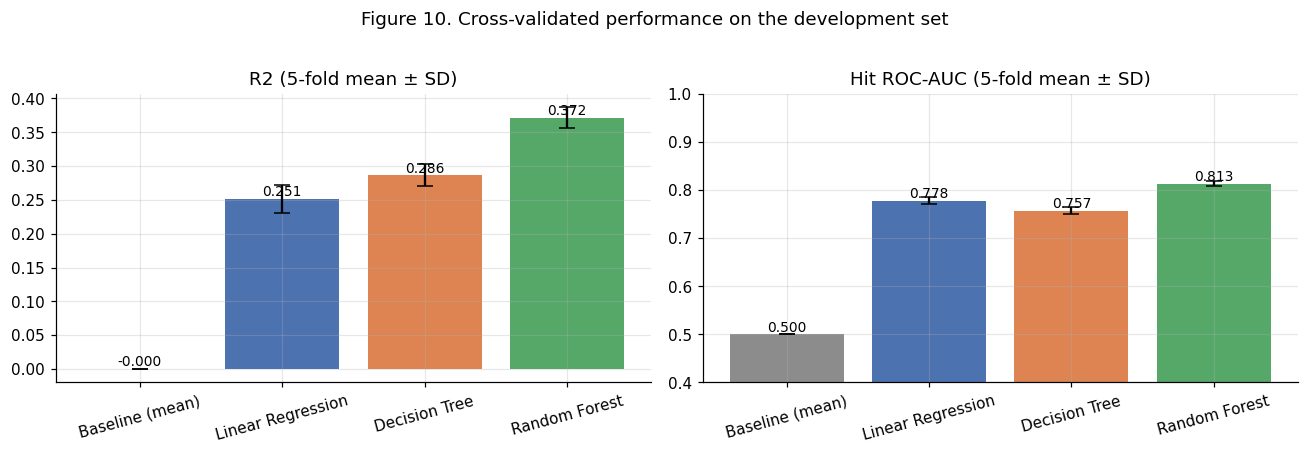

,MSE,RMSE,MAE,MAPE (%),R2,Hit ROC-AUC
Baseline (mean),0.288 ± 0.009,0.537 ± 0.008,0.409 ± 0.005,98.881 ± 1.579,-0.0 ± 0.0,0.5 ± 0.0
Linear Regression,0.216 ± 0.005,0.464 ± 0.005,0.339 ± 0.003,97.921 ± 4.798,0.251 ± 0.02,0.778 ± 0.007
Decision Tree,0.206 ± 0.005,0.454 ± 0.005,0.327 ± 0.004,100.33 ± 7.745,0.286 ± 0.016,0.757 ± 0.007
Random Forest,0.181 ± 0.004,0.425 ± 0.004,0.309 ± 0.003,89.593 ± 5.492,0.372 ± 0.016,0.813 ± 0.006


In [13]:
MODEL_ORDER = ["Baseline (mean)", "Linear Regression", "Decision Tree", "Random Forest"]
METRICS = ["MSE", "RMSE", "MAE", "MAPE (%)", "R2", "Hit ROC-AUC"]
means = pd.DataFrame({m: cv_results[m].mean() for m in MODEL_ORDER}).T[METRICS]
sds = pd.DataFrame({m: cv_results[m].std() for m in MODEL_ORDER}).T[METRICS]
table4 = means.round(3).astype(str) + " ± " + sds.round(3).astype(str)
means.join(sds, rsuffix=" SD").to_csv(os.path.join(TAB_DIR, "table4_cross_validation.csv"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["R2", "Hit ROC-AUC"]):
    ax.bar(MODEL_ORDER, means[metric], yerr=sds[metric], capsize=5, color=[MODEL_COLORS[m] for m in MODEL_ORDER])
    for i, v in enumerate(means[metric]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{metric} (5-fold mean ± SD)")
    ax.tick_params(axis="x", rotation=15)
axes[1].set_ylim(0.4, 1.0)
fig.suptitle("Figure 10. Cross-validated performance on the development set", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig10_cross_validation_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()
table4.style.set_caption("Table 4. 5-fold grouped cross-validation (mean ± SD), development set 2010–2021")

**Interpretation.**
- All three models improve clearly on the baseline. Random Forest is best on every metric used for selection: R² of 0.372 versus 0.286 (Decision Tree) and 0.251 (Linear Regression), the lowest MAE (0.309) and the highest hit ROC-AUC (0.813).
- Fold-to-fold standard deviations are small (about 0.02 for R²), so the ranking is not an artefact of a particular split: the gap between Random Forest and the Decision Tree (0.086) is more than five times the standard deviation.
- The advantage of the tree-based models over Linear Regression in R² is consistent with the non-linear relationships found in Notebook 2.
- MAPE is close to 100% for every model, including the baseline (98.9%), for the reasons given in Section 5.3; it does not discriminate between models on this target.
- An RMSE of about 0.43 on the log scale corresponds to a typical error factor of about 2.7 in owners (10^0.43). This reflects how much of a game's commercial outcome is not determined by information available at launch.

---
# 7. Validation

## 7.1 Hold-out test on 2022–2024 releases

Each model is refitted on the full development set with the settings selected above and evaluated
once on the hold-out set. This is the estimate of how the models would perform when forecasting
games released after the training data.

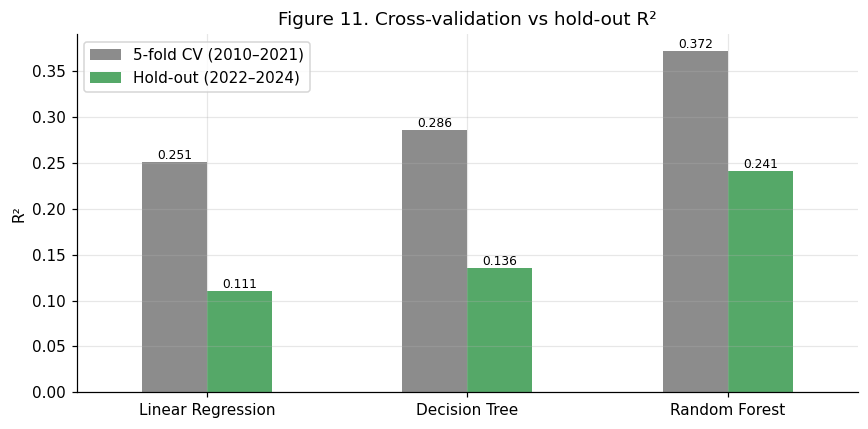

,MSE,RMSE,MAE,MAPE (%),R2,Hit ROC-AUC
Model,,,,,,
Baseline (mean),0.166,0.407,0.280,54.430,0.000,0.500
Linear Regression,0.148,0.384,0.275,80.075,0.111,0.831
Decision Tree,0.143,0.379,0.238,79.677,0.136,0.815
Random Forest,0.126,0.355,0.237,68.303,0.241,0.842


In [14]:
final_models = {
    "Baseline (mean)": baseline, "Linear Regression": lin_reg,
    "Decision Tree": decision_tree, "Random Forest": random_forest,
}
fitted, test_pred, holdout_rows = {}, {}, []
for name in MODEL_ORDER:
    fitted[name] = clone(final_models[name]).fit(dev[FEATURES_ALL], dev[TARGET])
    test_pred[name] = fitted[name].predict(test[FEATURES_ALL])
    holdout_rows.append({"Model": name, **compute_metrics(test, test_pred[name])})
table5 = pd.DataFrame(holdout_rows).set_index("Model")
table5.to_csv(os.path.join(TAB_DIR, "table5_holdout_test.csv"))

comparison = pd.DataFrame({"5-fold CV (2010–2021)": means["R2"], "Hold-out (2022–2024)": table5["R2"]})
ax = comparison.drop("Baseline (mean)").plot(kind="bar", figsize=(8, 4), color=[GREY, GREEN], rot=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("R²")
ax.set_title("Figure 11. Cross-validation vs hold-out R²")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig11_cv_vs_holdout.png"), dpi=150)
plt.show()
table5.style.format("{:.3f}").set_caption("Table 5. Hold-out test performance (games released Jan 2022 – Jun 2024)")

**Interpretation.**
- The ranking of the models is unchanged on unseen, later releases: Random Forest (R² 0.241, hit ROC-AUC 0.842) ahead of the Decision Tree (0.136, 0.815) and Linear Regression (0.111, 0.831).
- R² is lower than in cross-validation for every model, but this does not indicate that the models degrade. The hold-out target has a smaller spread (SD 0.407 versus 0.537 in the development set, about 43% less variance) because a larger share of recent games falls into the lowest owner range, and R² measures error relative to this smaller variance. In absolute terms errors are smaller on the hold-out set (Random Forest MAE 0.237 versus 0.309 in cross-validation), and hits are ranked better (ROC-AUC 0.842 versus 0.813).
- Linear Regression shows the largest drop in R² (0.251 → 0.111), suggesting that fixed linear effects transfer less well across periods than the threshold rules of the tree-based models.
- The baseline has the lowest MAPE (54%) while having no predictive value (R² = 0, ROC-AUC = 0.5), which confirms that MAPE is not a suitable selection criterion for this target.

## 7.2 Predicted versus actual values

The parent paper compared predicted and original sales visually (its Figures 2 and 3). Here the
comparison uses the hold-out set, so every prediction concerns a game the model has not seen.
Panel (a) plots each game; because owner estimates are reported in ranges, actual values form
horizontal bands. Panel (b) groups games into ten equal-sized bins by predicted value and compares
the average prediction with the average actual value in each bin; points on the diagonal indicate
well-calibrated predictions.

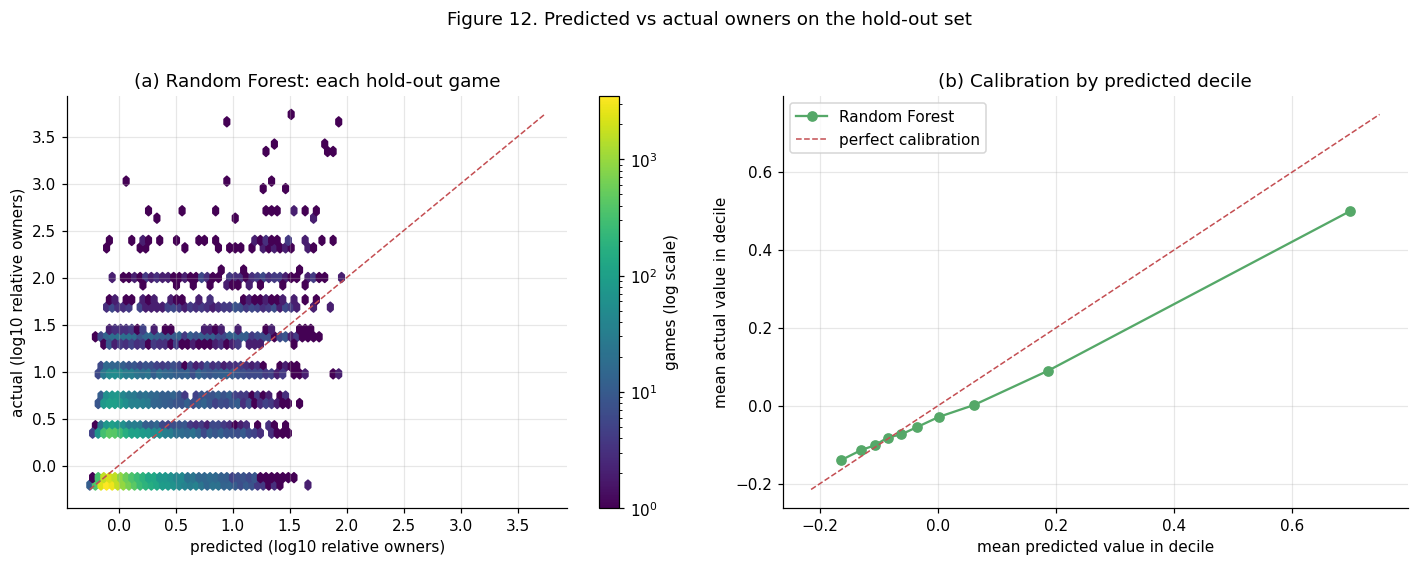

In [15]:
best = "Random Forest"
pred, actual = test_pred[best], test[TARGET].values

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(pred, actual, gridsize=45, bins="log", cmap="viridis", mincnt=1)
lims = [min(pred.min(), actual.min()), max(pred.max(), actual.max())]
axes[0].plot(lims, lims, color=RED, lw=1, ls="--")
axes[0].set_xlabel("predicted (log10 relative owners)")
axes[0].set_ylabel("actual (log10 relative owners)")
axes[0].set_title(f"(a) {best}: each hold-out game")
plt.colorbar(hb, ax=axes[0], label="games (log scale)")

deciles = pd.qcut(pred, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"pred": pred, "actual": actual, "decile": deciles}).groupby("decile").mean()
axes[1].plot(calib["pred"], calib["actual"], marker="o", color=GREEN, label=best)
lo, hi = calib.values.min() - 0.05, calib.values.max() + 0.05
axes[1].plot([lo, hi], [lo, hi], color=RED, ls="--", lw=1, label="perfect calibration")
axes[1].set_xlabel("mean predicted value in decile")
axes[1].set_ylabel("mean actual value in decile")
axes[1].set_title("(b) Calibration by predicted decile")
axes[1].legend()
fig.suptitle("Figure 12. Predicted vs actual owners on the hold-out set", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig12_predicted_vs_actual.png"), dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** Panel (a) shows the structure of the errors. Most games cluster in the lowest owner range and receive low predictions. The model rarely predicts more than about +2 (100 times the typical owner count), while the largest successes reach almost +4: exceptional hits are ranked highly, but their size is underestimated, which is the usual behaviour of an averaging model when extreme outcomes are rare. Panel (b) shows that predictions are well calibrated for the lowest eight deciles. The two highest deciles are over-predicted (about +0.19 predicted versus +0.09 actual, and +0.70 versus +0.50): the model identifies the right group of games but overstates how far above their cohort they will finish. Predictions are therefore more reliable as a ranking than as a point estimate of owners.

## 7.3 Contribution of release-day indicators

Release-day indicators (release quarter and launch-week competition) are known only once a release
date is fixed. Comparing the Random Forest with and without them shows how much accuracy is
available earlier in development, from store-page information alone.

In [16]:
tier_rows = []
for label, feats in [("Pre-release only", FEATURES_PRE), ("Pre-release + release-day", FEATURES_ALL)]:
    fm, _ = cross_validate_model(random_forest, feats)
    m = clone(random_forest).fit(dev[feats], dev[TARGET])
    ho = compute_metrics(test, m.predict(test[feats]))
    tier_rows.append({"Feature set": label, "Indicators": len(feats), "CV R2": fm["R2"].mean(),
                      "CV Hit ROC-AUC": fm["Hit ROC-AUC"].mean(), "Hold-out R2": ho["R2"],
                      "Hold-out Hit ROC-AUC": ho["Hit ROC-AUC"]})
table6 = pd.DataFrame(tier_rows).set_index("Feature set")
table6.to_csv(os.path.join(TAB_DIR, "table6_release_day_contribution.csv"))
table6.style.format({"Indicators": "{:d}", "CV R2": "{:.3f}", "CV Hit ROC-AUC": "{:.3f}",
                     "Hold-out R2": "{:.3f}", "Hold-out Hit ROC-AUC": "{:.3f}"}) \
    .set_caption("Table 6. Random Forest with and without release-day indicators")

,Indicators,CV R2,CV Hit ROC-AUC,Hold-out R2,Hold-out Hit ROC-AUC
Feature set,,,,,
Pre-release only,57,0.360,0.821,0.213,0.841
Pre-release + release-day,62,0.372,0.813,0.241,0.842


**Interpretation.** Store-page information alone accounts for most of the achievable accuracy. Without release-day indicators the Random Forest reaches a hold-out R² of 0.213 and a hit ROC-AUC of 0.841, about 88% of the full model's R² and essentially the same ranking quality. Adding release quarter and launch-week competition raises hold-out R² to 0.241 but does not improve the ranking of hits. A useful forecast is therefore available as soon as the store page is complete, before a release date is fixed.

## 7.4 Side analysis: launch-window critic score

The parent paper used critic score as a predictor. Metacritic scores are published around launch,
so they are legitimate release-day information, but only about 5% of Steam games have one. The
effect is therefore measured on that subset only, using 5-fold grouped cross-validation across all
release years (the subset is too small for a separate chronological hold-out).

In [17]:
mc = data[data["metacritic_score"].notna()].reset_index(drop=True)
mc_folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(mc, groups=mc["title_key"]))
mc_rows = []
for label, feats in [("Without Metacritic score", FEATURES_ALL), ("With Metacritic score", FEATURES_ALL + ["metacritic_score"])]:
    fm, _ = cross_validate_model(random_forest, feats, frame=mc, fold_list=mc_folds)
    mc_rows.append({"Feature set": label, "Games": len(mc), "CV R2": fm["R2"].mean(), "CV R2 SD": fm["R2"].std(),
                    "CV Hit ROC-AUC": fm["Hit ROC-AUC"].mean()})
table7 = pd.DataFrame(mc_rows).set_index("Feature set")
table7.to_csv(os.path.join(TAB_DIR, "table7_metacritic_subset.csv"))
print(f"Hit rate in the Metacritic subset: {mc['is_hit'].mean():.1%} (all games: {data['is_hit'].mean():.1%})")
table7.style.format({"Games": "{:,}", "CV R2": "{:.3f}", "CV R2 SD": "{:.3f}", "CV Hit ROC-AUC": "{:.3f}"}) \
    .set_caption("Table 7. Random Forest on games with a Metacritic score (5-fold grouped CV)")

Hit rate in the Metacritic subset: 61.2% (all games: 10.3%)


,Games,CV R2,CV R2 SD,CV Hit ROC-AUC
Feature set,,,,
Without Metacritic score,"3,618",0.403,0.055,0.664
With Metacritic score,"3,618",0.449,0.047,0.687


**Interpretation.** Games with a Metacritic score are an unrepresentative subset: 61% of them are hits, compared with 10% of all games, because critics mainly review larger releases. For the same reason, separating hits from non-hits is harder within this subset, which explains its lower ROC-AUC. Adding the critic score raises cross-validated R² from 0.403 to 0.449 and hit ROC-AUC from 0.664 to 0.687. The gain is real but modest — about one fold-to-fold standard deviation (≈ 0.05) — and applies to only 5% of games. Critic reception adds information beyond the store page, but it cannot be used for most releases and is therefore kept out of the main model.

---
# 8. Decision Making

## 8.1 Model selection

The selection criteria, in order of priority:
1. **Hold-out performance** (R² and hit ROC-AUC), because it reflects the intended use on future releases;
2. **Stability** across cross-validation folds;
3. **Interpretability**, where accuracy is similar.

In [18]:
selection = pd.DataFrame({
    "CV R2 (mean)": means["R2"], "CV R2 (SD)": sds["R2"],
    "Hold-out R2": table5["R2"], "Hold-out MAE": table5["MAE"], "Hold-out Hit ROC-AUC": table5["Hit ROC-AUC"],
    "Interpretability": ["-", "High (coefficients)", "High (rules)", "Moderate (importance)"],
}).loc[MODEL_ORDER]
selection.style.format({c: "{:.3f}" for c in selection.columns if c != "Interpretability"}) \
    .set_caption("Model selection summary")

,CV R2 (mean),CV R2 (SD),Hold-out R2,Hold-out MAE,Hold-out Hit ROC-AUC,Interpretability
Baseline (mean),-0.000,0.000,0.000,0.280,0.500,-
Linear Regression,0.251,0.020,0.111,0.275,0.831,High (coefficients)
Decision Tree,0.286,0.016,0.136,0.238,0.815,High (rules)
Random Forest,0.372,0.016,0.241,0.237,0.842,Moderate (importance)


**Decision.** **Random Forest** is selected. It has the highest hold-out R² (0.241) and hit ROC-AUC (0.842), the lowest hold-out MAE (0.237, level with the Decision Tree), and the highest cross-validated R², with fold-to-fold variation comparable to the other models. Its lower interpretability is addressed by the permutation-importance analysis below. Where transparent decision rules are required, the tuned Decision Tree is a simpler alternative at a moderate loss of accuracy (hold-out R² 0.136).

## 8.2 Key drivers of predicted sales

**Method.** Permutation importance on the hold-out set: the values of one indicator group are
shuffled across games, breaking their link with the target, and the resulting drop in hold-out R²
is recorded (mean of five repetitions). Groups are shuffled as a whole because related columns
(for example, the three localisation indicators) carry overlapping information; shuffling one
column at a time would understate their joint contribution. Computing importance on the hold-out
set measures what the model relies on when predicting unseen games. To indicate the direction of
each effect, the last column names the indicator in the group with the largest standardised
Linear Regression coefficient, with its sign.

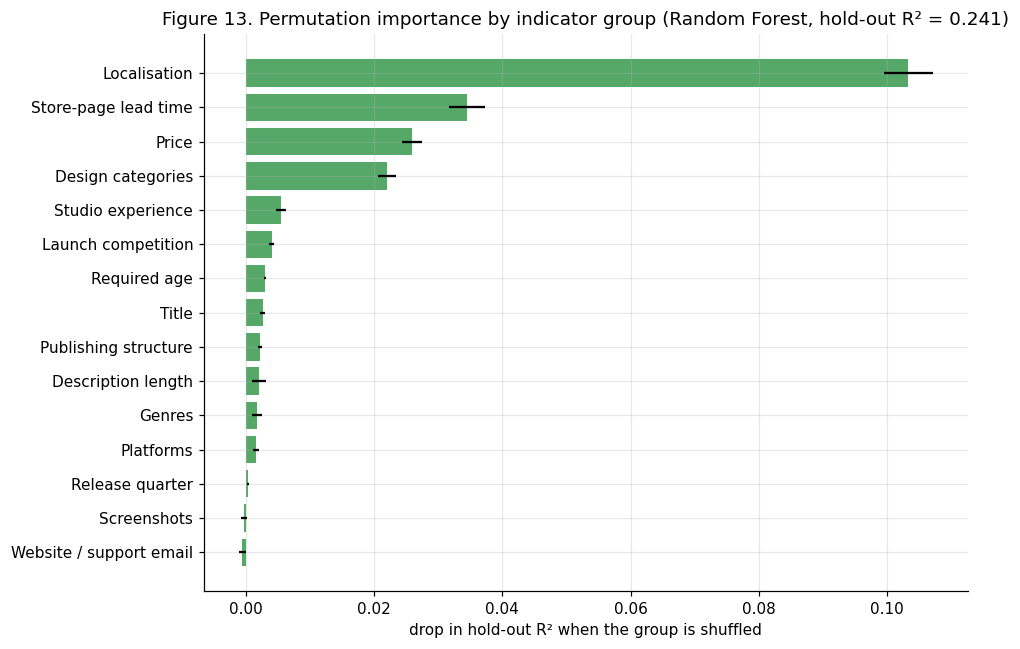

,R2 drop,SD,Strongest LR indicator
Indicator group,,,
Localisation,0.1033,0.0039,+ log_n_languages
Store-page lead time,0.0345,0.0028,+ log_lead_days
Price,0.0259,0.0016,+ is_free
Design categories,0.0221,0.0014,+ cat_Steam_Cloud
Studio experience,0.0055,0.0008,+ log_pub_prior_releases
Launch competition,0.0041,0.0004,+ log_same_week_releases
Required age,0.0030,0.0002,+ required_age
Title,0.0027,0.0003,+ has_sequel_marker
Publishing structure,0.0022,0.0003,− self_published


In [19]:
rng = np.random.default_rng(RANDOM_STATE)
rf_final = fitted["Random Forest"]
base_r2 = r2_score(test[TARGET], rf_final.predict(test[FEATURES_ALL]))
imp_rows = []
for group, cols in GROUPS.items():
    drops = []
    for _ in range(5):
        shuffled = test[FEATURES_ALL].copy()
        shuffled[cols] = shuffled[cols].values[rng.permutation(len(shuffled))]
        drops.append(base_r2 - r2_score(test[TARGET], rf_final.predict(shuffled)))
    main = coef[cols].abs().idxmax()
    imp_rows.append({"Indicator group": group, "R2 drop": np.mean(drops), "SD": np.std(drops),
                     "Strongest LR indicator": f"{'+' if coef[main] > 0 else '−'} {main}"})
importance = pd.DataFrame(imp_rows).sort_values("R2 drop", ascending=False).set_index("Indicator group")
importance.to_csv(os.path.join(TAB_DIR, "table8_permutation_importance.csv"))

imp = importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp["R2 drop"], xerr=imp["SD"], color=GREEN)
ax.set_xlabel("drop in hold-out R² when the group is shuffled")
ax.set_title(f"Figure 13. Permutation importance by indicator group (Random Forest, hold-out R² = {base_r2:.3f})")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig13_permutation_importance.png"), dpi=150)
plt.show()
importance.style.format({"R2 drop": "{:.4f}", "SD": "{:.4f}"}).set_caption("Table 8. Permutation importance on the hold-out set")

**Interpretation.**
- **Localisation** is by far the most important group: shuffling it removes 0.103 of the 0.241 hold-out R². More supported languages are associated with more owners (Linear Regression coefficient +0.097 per SD); the forest also captures the non-linear peak at 9–15 languages seen in Notebook 2.
- **Store-page lead time** (0.035) and **price** (0.026) follow. A longer marketing period before launch, and either a higher list price or a free-to-play model, are associated with higher sales relative to the release cohort.
- **Design categories** (0.022): the largest linear effects within this group are cloud saves, online co-op and online PvP.
- The remaining groups each add less than 0.006. Screenshots and the website/support e-mail flags contribute nothing once the other indicators are known: their relationships in Notebook 2 overlap with localisation, price and lead time, which measure production scale more directly.

These are associations learned from historical data, not causal effects. Adding languages to a small game would not necessarily increase its sales, because the number of languages also reflects budget and publisher backing.

## 8.3 Practical use: screening upcoming releases

A publisher or platform rarely needs an exact owner count; a more common decision is **which
upcoming games to prioritise** for investment, featuring or marketing support. This is a ranking
task. The cumulative gains curve below ranks hold-out games by the Random Forest's prediction and
shows the share of all hits captured when only the top-ranked games are selected.

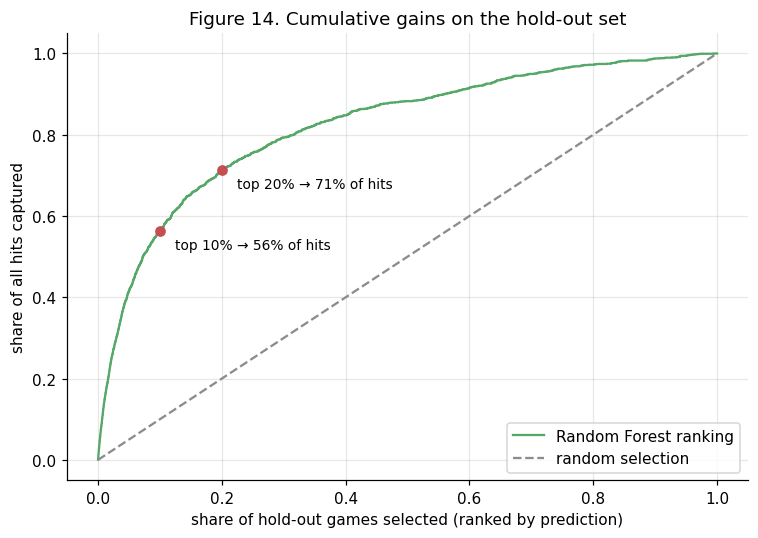

Hold-out hit rate (all games): 5.4%


,Games,Hit rate,Lift vs average,Share of all hits captured
Top share selected,,,,
1%,285,77.5%,14.3x,14.2%
5%,"1,429",45.1%,8.3x,41.6%
10%,"2,859",30.5%,5.6x,56.3%
20%,"5,719",19.3%,3.6x,71.3%


In [20]:
order = np.argsort(-test_pred["Random Forest"])
hits_sorted = test["is_hit"].values[order]
share_games = np.arange(1, len(order) + 1) / len(order)
share_hits = np.cumsum(hits_sorted) / hits_sorted.sum()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(share_games, share_hits, color=GREEN, label="Random Forest ranking")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="random selection")
for q in (0.10, 0.20):
    k = int(q * len(order))
    ax.scatter(q, share_hits[k - 1], color=RED, zorder=3)
    ax.annotate(f"top {q:.0%} → {share_hits[k - 1]:.0%} of hits", (q, share_hits[k - 1]),
                textcoords="offset points", xytext=(10, -12), fontsize=9)
ax.set_xlabel("share of hold-out games selected (ranked by prediction)")
ax.set_ylabel("share of all hits captured")
ax.set_title("Figure 14. Cumulative gains on the hold-out set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig14_cumulative_gains.png"), dpi=150)
plt.show()

base = test["is_hit"].mean()
gain_rows = []
for q in (0.01, 0.05, 0.10, 0.20):
    k = int(q * len(order))
    hr = hits_sorted[:k].mean()
    gain_rows.append({"Top share selected": f"{q:.0%}", "Games": k, "Hit rate": hr, "Lift vs average": hr / base,
                      "Share of all hits captured": share_hits[k - 1]})
print(f"Hold-out hit rate (all games): {base:.1%}")
pd.DataFrame(gain_rows).set_index("Top share selected").style.format(
    {"Games": "{:,}", "Hit rate": "{:.1%}", "Lift vs average": "{:.1f}x", "Share of all hits captured": "{:.1%}"})

**Interpretation.** The ranking is highly concentrated at the top. Among the 1% of hold-out games the model ranks highest, 77.5% became hits, 14.3 times the average rate of 5.4%. The top 10% of the ranking contains 56% of all hits in the hold-out period, and the top 20% contains 71%. A publisher, investor or storefront reviewing only the highest-ranked tenth of upcoming releases would therefore find more than half of the eventual commercial successes, using information available before launch.

## 8.4 Comparison with the parent paper

In [21]:
paper_comparison = pd.DataFrame([
    {"Study": "Gray et al. (2024)", "Data": "VGChartz, 1980–2020",
     "Predictors": "Regional sales (sum to target), critic score/count, user count",
     "Validation": "Orange Test & Score (random)",
     "Linear Regression R2": 1.000, "Decision Tree R2": 0.939, "Random Forest R2": np.nan},
    {"Study": "This study", "Data": "Steam, 2010–2024",
     "Predictors": "Pre-release and release-day indicators only",
     "Validation": "5-fold grouped CV + chronological hold-out",
     "Linear Regression R2": table5.loc["Linear Regression", "R2"],
     "Decision Tree R2": table5.loc["Decision Tree", "R2"],
     "Random Forest R2": table5.loc["Random Forest", "R2"]},
]).set_index("Study")
paper_comparison.to_csv(os.path.join(TAB_DIR, "table9_parent_paper_comparison.csv"))
paper_comparison.style.format({c: "{:.3f}" for c in ["Linear Regression R2", "Decision Tree R2", "Random Forest R2"]}, na_rep="—") \
    .set_caption("Table 9. Comparison with the parent paper (this study: hold-out R²)")

,Data,Predictors,Validation,Linear Regression R2,Decision Tree R2,Random Forest R2
Study,,,,,,
Gray et al. (2024),"VGChartz, 1980–2020","Regional sales (sum to target), critic score/count, user count",Orange Test & Score (random),1.000,0.939,—
This study,"Steam, 2010–2024",Pre-release and release-day indicators only,5-fold grouped CV + chronological hold-out,0.111,0.136,0.241


**Interpretation.** The parent paper's near-perfect accuracy (R² = 1.000) came from predictors that are components of the target (regional sales) or that accumulate after release (user count), evaluated on a random split. Under a design in which every predictor is available before launch and the test set lies in the future, the same two methods achieve R² of 0.111 (Linear Regression) and 0.136 (Decision Tree), and Random Forest 0.241. These lower figures are the realistic accuracy of a pre-release forecast. The ordering of the methods also changes: the parent paper preferred Linear Regression, whereas here both tree-based models achieve higher R², because genuine pre-release relationships are non-linear.

## 8.5 Limitations

- **Target measurement.** SteamSpy owner counts are estimates reported in ranges, not audited sales, and the binned target caps the achievable R². Free games count as owned once added to a library, which inflates their owner counts relative to paid sales.
- **Snapshot values.** Store-page fields are observed at the 2025 snapshot. Most are fixed at launch, but some (for example, supported languages or the pricing model) can change later. The leakage audit removed the fields most prone to change, but minor post-launch edits cannot be ruled out.
- **Missing labels.** About 20% of games released from 2021 onwards lack an owner estimate and were excluded. They are probably mostly small releases, so the sample over-represents games that attracted some attention.
- **Cohort-relative target.** The model predicts performance relative to other games released in the same year. Converting predictions into absolute owner counts requires an estimate of the average for the release year, which is not known in advance.
- **Scope.** The analysis covers PC games on Steam only. Console sales, and demand signals such as wishlists or pre-release media coverage, are not available in the dataset.

## 8.6 Conclusion

This study re-examined the parent paper's approach to video game sales prediction under a strict leakage-free design. Using only information available before or at release, Random Forest predicts a Steam game's owners relative to its release cohort with a hold-out R² of 0.241 and ranks eventual hits with a ROC-AUC of 0.842; the top 10% of its ranking captures 56% of all hits. Localisation, store-page lead time, price and multiplayer design are the most informative pre-release indicators. Sales can be forecast meaningfully before launch, but with far lower precision than the parent paper reported, and the practical value of such a model lies in ranking and screening upcoming releases rather than in precise point forecasts.